In [1]:
# Install dependencies (jalankan sekali saja)
%pip install requests joblib numpy pandas scikit-learn matplotlib seaborn lightgbm tqdm nltk ipykernel

     ---------------------------------------- 64.7/64.7 KB 3.6 MB/s eta 0:00:00
     -------------------------------------- 309.1/309.1 KB 4.7 MB/s eta 0:00:00
     ---------------------------------------- 15.9/15.9 MB 2.5 MB/s eta 0:00:00
     ---------------------------------------- 11.4/11.4 MB 2.6 MB/s eta 0:00:00
     ---------------------------------------- 11.2/11.2 MB 2.6 MB/s eta 0:00:00
     ---------------------------------------- 7.8/7.8 MB 2.7 MB/s eta 0:00:00
     -------------------------------------- 294.9/294.9 KB 6.1 MB/s eta 0:00:00
     ---------------------------------------- 1.5/1.5 MB 3.5 MB/s eta 0:00:00
     ---------------------------------------- 80.2/80.2 KB 2.3 MB/s eta 0:00:00
     ---------------------------------------- 1.5/1.5 MB 3.8 MB/s eta 0:00:00
     ---------------------------------------- 69.6/69.6 KB 4.0 MB/s eta 0:00:00
     -------------------------------------- 215.8/215.8 KB 6.4 MB/s eta 0:00:00
     -------------------------------------- 13

You should consider upgrading via the 'c:\Users\Raihan_M_R\AppData\Local\Programs\Python\Python39\python.exe -m pip install --upgrade pip' command.


# 🎮 Video Games Sentiment Analysis (Analisis Sentimen Ulasan Video Games)

Notebook ini mengimplementasikan alur lengkap analisis sentimen berbasis **Natural Language Processing (NLP)** dan **Machine Learning** pada dataset **Amazon Reviews 2023** kategori **Video_Games**.

### Alur Proyek:
1. **Persiapan Lingkungan & Pustaka**
2. **Pengunduhan & Pemuatan Data Bertahap (Streaming / Chunking)** (Filter timestamp $\le 31$ Des 2019)
3. **Pembersihan Data & Pelabelan (Preprocessing)** (Buang rating 3, label biner 0 & 1, gabung `full_text`)
4. **Pembagian Data (Train-Validation Split)** (Time-based Split & Stratified Split)
5. **Ekstraksi Fitur & Pemodelan Machine Learning (Pipeline TF-IDF)**
6. **Evaluasi dengan Metrik Macro-F1 & Hyperparameter Tuning**
   - Evaluasi `f1_score(average='macro')` dan `classification_report`
   - Tuning nilai regulasi $C$ pada Logistic Regression
   - Tuning ambang batas probabilitas (*Optimal Probability Threshold Tuning*)
7. **Penyimpanan Model Terlatih Terbaik** (`model/model_sentimen.joblib`)
8. **Pengujian Inferensi Real-time**

## 1. Persiapan Lingkungan & Pemuatan Pustaka

In [2]:
import os
import re
import gzip
import json
import zlib
import time
import datetime
import requests
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import MultinomialNB
from sklearn.calibration import CalibratedClassifierCV
from lightgbm import LGBMClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    f1_score, classification_report, accuracy_score, 
    precision_score, recall_score, confusion_matrix
)

sns.set_theme(style="whitegrid")
print("Pustaka berhasil dimuat!")

Pustaka berhasil dimuat!


## 2. Pengunduhan & Pemuatan Data secara Bertahap (Chunking/Streaming)

> **Penting:** Membaca data `.jsonl.gz` besar secara streaming baris demi baris menggunakan `json.loads` dengan filter ulasan `timestamp <= 1577836799999` (hingga 31 Desember 2019 UTC) untuk mencegah kehabisan memori RAM.

In [3]:
URL_VIDEO_GAMES = "https://mcauleylab.ucsd.edu/public_datasets/data/amazon_2023/raw/review_categories/Video_Games.jsonl.gz"
CUTOFF_TIMESTAMP = 1577836799999  # 31 Desember 2019 23:59:59.999 UTC

raw_csv_path = os.path.join("data", "video_games_reviews_2019.csv")
if os.path.exists(raw_csv_path):
    print(f"Memuat data ulasan dari berkas lokal: {raw_csv_path}")
    df = pd.read_csv(raw_csv_path)
else:
    from load_data import stream_reviews_from_url
    records = list(stream_reviews_from_url(max_records=5000))
    df = pd.DataFrame(records)
    os.makedirs("data", exist_ok=True)
    df.to_csv(raw_csv_path, index=False)

print(f"Total baris data awal: {len(df)}")
print(f"Maksimum timestamp   : {df['timestamp'].max()} (Batas: {CUTOFF_TIMESTAMP})")
print(f"Rentang tanggal      : {df['date'].min()} s/d {df['date'].max()}")
print("Verifikasi <= 2019   :", (df['timestamp'] <= CUTOFF_TIMESTAMP).all())
df.head()

Memuat data ulasan dari berkas lokal: data\video_games_reviews_2019.csv
Total baris data awal: 4894
Maksimum timestamp   : 1577835470295 (Batas: 1577836799999)
Rentang tanggal      : 1999-12-07 23:40:01 s/d 2019-12-31 23:37:50
Verifikasi <= 2019   : True


,rating,title,text,timestamp,date,year,asin,verified_purchase,helpful_vote,sentiment
0,5.0,... an order for my kids & they have really en...,This was an order for my kids & they have real...,1490877431000,2017-03-30 12:37:11,2017,B01FEHJYUU,True,0,1.0
1,5.0,Great alt to pro controller,"These work great, They use batteries which is ...",1577637634017,2019-12-29 16:40:34,2019,B07GXJHRVK,True,0,1.0
2,5.0,solid product,I would recommend to anyone looking to add jus...,1427591932000,2015-03-29 01:18:52,2015,B00HUWA45W,True,0,1.0
3,3.0,love all the amazing colors but the black is r...,love all the amazing colors but the black is r...,1518124539574,2018-02-08 21:15:39,2018,B016Y2BVKA,True,0,NaN
4,4.0,good,"good, a tad bit too bulky, but good. they stay...",1523314072900,2018-04-09 22:47:52,2018,B001AW156U,True,0,1.0


## 3. Pembersihan Data & Pelabelan (Preprocessing)

1. Membuang baris dengan `rating == 3` (ulasan netral) atau nilai kosong pada `rating`, `title`, dan `text`.
2. Membuat label biner: rating 1, 2 $\rightarrow$ `0` (Negatif); rating 4, 5 $\rightarrow$ `1` (Positif).
3. Menggabungkan `full_text = title + " " + text`.
4. Pembersihan dasar: menghapus tag HTML, URL, karakter tidak relevan, dan normalisasi spasi.

In [4]:
preprocessed_csv = os.path.join("data", "video_games_preprocessed.csv")
if os.path.exists(preprocessed_csv):
    print(f"Memuat dataset preprocessing dari: {preprocessed_csv}")
    df_clean = pd.read_csv(preprocessed_csv)
else:
    from load_data import preprocess_reviews_dataframe
    df_clean = preprocess_reviews_dataframe(df)
    df_clean.to_csv(preprocessed_csv, index=False)

print(f"Total data bersih: {len(df_clean)} sampel")
print("Distribusi Label Biner:")
print(df_clean["label"].value_counts())
df_clean[["rating", "title", "label", "clean_text"]].head()

Memuat dataset preprocessing dari: data\video_games_preprocessed.csv
Total data bersih: 4482 sampel
Distribusi Label Biner:
label
1    3902
0     580
Name: count, dtype: int64


,rating,title,label,clean_text
0,5.0,... an order for my kids & they have really en...,1,... an order for my kids they have really enjo...
1,5.0,Great alt to pro controller,1,"Great alt to pro controller These work great, ..."
2,5.0,solid product,1,solid product I would recommend to anyone look...
3,4.0,good,1,"good good, a tad bit too bulky, but good. they..."
4,1.0,It does not fasten itself to the bottom of the...,0,It does not fasten itself to the bottom of the...


## 4. Pembagian Data (Train-Validation Split)

- **Time-based Split**: Ulasan $\le 2018$ (Train) vs $2019$ (Validation) untuk menyimulasikan prediksi ulasan masa depan.
- **Stratified Split**: Pembagian acak 80:20 terstratifikasi menjaga proporsi kelas negatif (~12.94%) tetap konsisten.

In [5]:
# 1. Time-based Split
train_time_df = df_clean[df_clean["year"] <= 2018].copy()
val_time_df = df_clean[df_clean["year"] == 2019].copy()
X_train_time, y_train_time = train_time_df["clean_text"], train_time_df["label"]
X_val_time, y_val_time = val_time_df["clean_text"], val_time_df["label"]

# 2. Stratified Split (80:20)
X_train_strat, X_val_strat, y_train_strat, y_val_strat = train_test_split(
    df_clean["clean_text"], df_clean["label"], test_size=0.2, random_state=42, stratify=df_clean["label"]
)

print(f"Time-based Split : Train = {len(X_train_time)} sampel, Val = {len(X_val_time)} sampel")
print(f"Stratified Split : Train = {len(X_train_strat)} sampel, Val = {len(X_val_strat)} sampel")

Time-based Split : Train = 3537 sampel, Val = 945 sampel
Stratified Split : Train = 3585 sampel, Val = 897 sampel


## 5. Ekstraksi Fitur & Pipeline Pemodelan (TF-IDF + Class Imbalance Handling)

- **`TfidfVectorizer`**: `ngram_range=(1, 2)` dengan pengecualian kata negasi (*not*, *no*, *never*) dari stop words untuk menangkap frasa seperti *"not good"*.
- Parameter `class_weight='balanced'` pada model linier untuk mengatasi ketidakseimbangan kelas.

In [6]:
# Pertahankan kata negasi dalam stop words
negation_words = {'not', 'no', 'never', 'neither', 'nobody', 'none', 'nor', 'nothing', 'nowhere', 'hardly', 'barely', 'scarcely'}
custom_stop_words = list(ENGLISH_STOP_WORDS - negation_words)

def build_pipeline(c_value=1.0):
    return Pipeline([
        ("tfidf", TfidfVectorizer(
            max_features=20000,
            ngram_range=(1, 2),
            sublinear_tf=True,
            stop_words=custom_stop_words
        )),
        ("classifier", LogisticRegression(
            C=c_value,
            max_iter=1000,
            class_weight="balanced",
            random_state=42
        ))
    ])

# Model baseline (C = 1.0)
base_pipeline = build_pipeline(c_value=1.0)
base_pipeline.fit(X_train_strat, y_train_strat)
print("Model baseline Logistic Regression (C=1.0) selesai dilatih!")

Model baseline Logistic Regression (C=1.0) selesai dilatih!


## 6. Evaluasi dengan Metrik Macro-F1 & Hyperparameter Tuning

> **Mengapa Menggunakan Macro-F1?**  
> Pada dataset dengan ketidakseimbangan kelas (87% Positif vs 13% Negatif), akurasi standar dapat menyesatkan karena model yang selalu menebak 'Positif' tetap bisa meraih akurasi 87%.  
> **Macro-F1** menghitung rata-rata tanpa bobot dari kedua kelas:
> $$\text{Macro-F1} = \frac{F1_{\text{Negatif}} + F1_{\text{Positif}}}{2}$$
> Hal ini memastikan performa pada ulasan negatif dan positif dinilai sama pentingnya tanpa berat sebelah.

Langkah tuning:
1. **Tuning Nilai $C$ (Regularisasi)** pada Logistic Regression untuk meningkatkan kapasitas model dalam mengenali pola ulasan negatif.
2. **Tuning Ambang Batas Probabilitas (*Threshold Tuning*)**: Mencari nilai batas optimal untuk memprediksi sentimen berdasarkan probabilitas kelas positif $P(Y=1)$.

In [7]:
# A. Prediksi dan Evaluasi Model Baseline
y_pred_base = base_pipeline.predict(X_val_strat)
macro_f1_base = f1_score(y_val_strat, y_pred_base, average="macro")
acc_base = accuracy_score(y_val_strat, y_pred_base)

print("=" * 65)
print(f"EVALUASI BASELINE (C=1.0) | Macro-F1: {macro_f1_base:.4f} | Akurasi: {acc_base*100:.2f}%")
print("=" * 65)
print(classification_report(y_val_strat, y_pred_base, target_names=["Negatif (0)", "Positif (1)"]))

# B. Tuning Nilai Regularisasi C
c_candidates = [0.1, 0.5, 1.0, 2.0, 5.0, 10.0]
tuning_c_results = []

for c in c_candidates:
    pipe = build_pipeline(c_value=c)
    pipe.fit(X_train_strat, y_train_strat)
    preds = pipe.predict(X_val_strat)
    
    tuning_c_results.append({
        "C": c,
        "Accuracy": accuracy_score(y_val_strat, preds),
        "Precision (Neg)": precision_score(y_val_strat, preds, pos_label=0),
        "Recall (Neg)": recall_score(y_val_strat, preds, pos_label=0),
        "F1 (Negatif)": f1_score(y_val_strat, preds, pos_label=0),
        "F1 (Positif)": f1_score(y_val_strat, preds, pos_label=1),
        "Macro-F1": f1_score(y_val_strat, preds, average="macro")
    })

df_c_tuning = pd.DataFrame(tuning_c_results)
best_c = df_c_tuning.sort_values(by="Macro-F1", ascending=False).iloc[0]["C"]
print("Hasil Tuning Nilai C:")
print(df_c_tuning.to_string(index=False))
print(f"\nNilai C terbaik: {best_c}")

EVALUASI BASELINE (C=1.0) | Macro-F1: 0.8360 | Akurasi: 91.97%
              precision    recall  f1-score   support

 Negatif (0)       0.66      0.79      0.72       116
 Positif (1)       0.97      0.94      0.95       781

    accuracy                           0.92       897
   macro avg       0.81      0.87      0.84       897
weighted avg       0.93      0.92      0.92       897

Hasil Tuning Nilai C:
   C  Accuracy  Precision (Neg)  Recall (Neg)  F1 (Negatif)  F1 (Positif)  Macro-F1
 0.1  0.874025         0.507614      0.862069      0.638978      0.923700  0.781339
 0.5  0.903010         0.592357      0.801724      0.681319      0.942801  0.812060
 1.0  0.919732         0.657143      0.793103      0.718750      0.953186  0.835968
 2.0  0.933110         0.722222      0.784483      0.752066      0.961340  0.856703
 5.0  0.940914         0.788991      0.741379      0.764444      0.966221  0.865332
10.0  0.943144         0.809524      0.732759      0.769231      0.967578  0.868404


In [8]:
# C. Tuning Ambang Batas Probabilitas (Optimal Probability Threshold Tuning)
# Latih model dengan C terbaik
tuned_pipeline = build_pipeline(c_value=best_c)
tuned_pipeline.fit(X_train_strat, y_train_strat)

# Dapatkan estimasi probabilitas untuk kelas positif P(Y=1)
val_probs_pos = tuned_pipeline.predict_proba(X_val_strat)[:, 1]

threshold_candidates = np.linspace(0.3, 0.8, 26)
threshold_evals = []

for thresh in threshold_candidates:
    preds_thresh = (val_probs_pos >= thresh).astype(int)
    threshold_evals.append({
        "Threshold": round(thresh, 3),
        "Accuracy": accuracy_score(y_val_strat, preds_thresh),
        "Precision (Neg)": precision_score(y_val_strat, preds_thresh, pos_label=0, zero_division=0),
        "Recall (Neg)": recall_score(y_val_strat, preds_thresh, pos_label=0),
        "F1 (Negatif)": f1_score(y_val_strat, preds_thresh, pos_label=0),
        "F1 (Positif)": f1_score(y_val_strat, preds_thresh, pos_label=1),
        "Macro-F1": f1_score(y_val_strat, preds_thresh, average="macro")
    })

df_threshold = pd.DataFrame(threshold_evals)
best_thresh_row = df_threshold.sort_values(by="Macro-F1", ascending=False).iloc[0]
best_threshold = best_thresh_row["Threshold"]

print(f"Ambang batas optimal: P(Y=1) >= {best_threshold}")
print(f"Macro-F1 Optimal : {best_thresh_row['Macro-F1']:.4f}")
print(f"F1 Kelas Negatif : {best_thresh_row['F1 (Negatif)']:.4f}")
print(f"F1 Kelas Positif : {best_thresh_row['F1 (Positif)']:.4f}")

Ambang batas optimal: P(Y=1) >= 0.52
Macro-F1 Optimal : 0.8704
F1 Kelas Negatif : 0.7733
F1 Kelas Positif : 0.9675


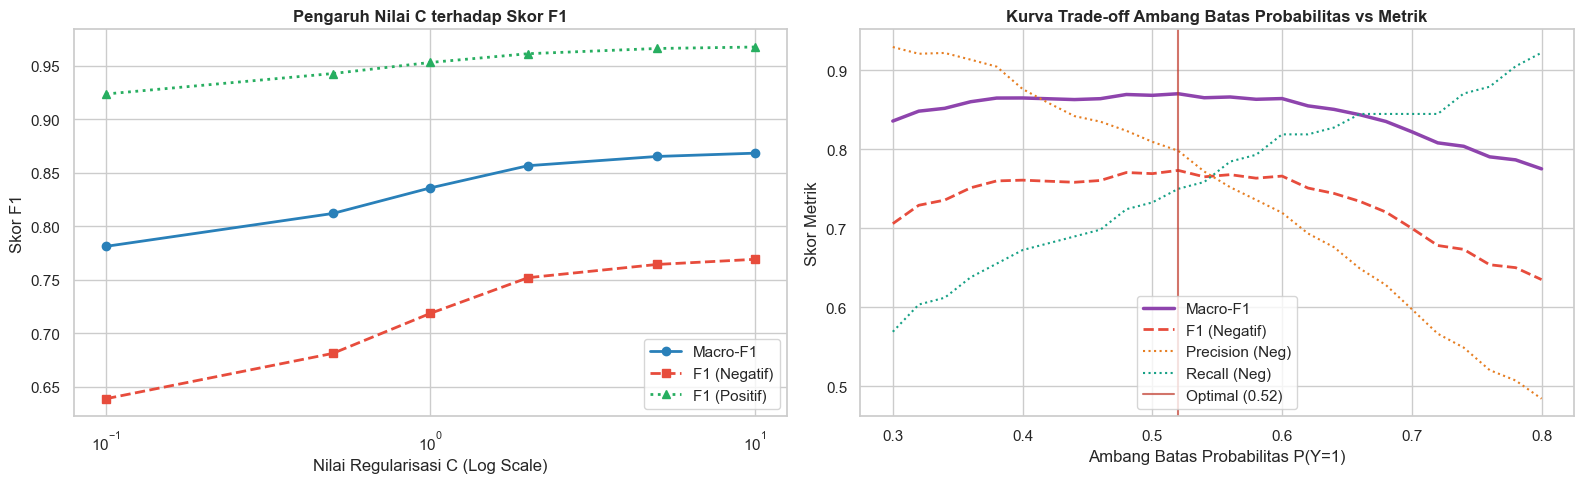

In [9]:
# Visualisasi Analisis Tuning: Pengaruh C dan Kurva Trade-off Threshold
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# 1. Plot C vs Macro-F1
axes[0].plot(df_c_tuning["C"], df_c_tuning["Macro-F1"], marker="o", color="#2980b9", linewidth=2, label="Macro-F1")
axes[0].plot(df_c_tuning["C"], df_c_tuning["F1 (Negatif)"], marker="s", color="#e74c3c", linewidth=2, linestyle="--", label="F1 (Negatif)")
axes[0].plot(df_c_tuning["C"], df_c_tuning["F1 (Positif)"], marker="^", color="#27ae60", linewidth=2, linestyle=":", label="F1 (Positif)")
axes[0].set_xscale("log")
axes[0].set_title("Pengaruh Nilai C terhadap Skor F1", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Nilai Regularisasi C (Log Scale)")
axes[0].set_ylabel("Skor F1")
axes[0].legend()

# 2. Plot Threshold vs Metrik
axes[1].plot(df_threshold["Threshold"], df_threshold["Macro-F1"], color="#8e44ad", linewidth=2.5, label="Macro-F1")
axes[1].plot(df_threshold["Threshold"], df_threshold["F1 (Negatif)"], color="#e74c3c", linewidth=2, linestyle="--", label="F1 (Negatif)")
axes[1].plot(df_threshold["Threshold"], df_threshold["Precision (Neg)"], color="#e67e22", linewidth=1.5, linestyle=":", label="Precision (Neg)")
axes[1].plot(df_threshold["Threshold"], df_threshold["Recall (Neg)"], color="#16a085", linewidth=1.5, linestyle=":", label="Recall (Neg)")
axes[1].axvline(x=best_threshold, color="#c0392b", linestyle="-", alpha=0.7, label=f"Optimal ({best_threshold})")
axes[1].set_title("Kurva Trade-off Ambang Batas Probabilitas vs Metrik", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Ambang Batas Probabilitas P(Y=1)")
axes[1].set_ylabel("Skor Metrik")
axes[1].legend()

plt.tight_layout()
plt.show()

LAPORAN KLASIFIKASI SESUDAH TUNING (C=10.0, Threshold=0.52)
Akurasi: 94.31% | Macro-F1: 0.8704
              precision    recall  f1-score   support

 Negatif (0)       0.80      0.75      0.77       116
 Positif (1)       0.96      0.97      0.97       781

    accuracy                           0.94       897
   macro avg       0.88      0.86      0.87       897
weighted avg       0.94      0.94      0.94       897



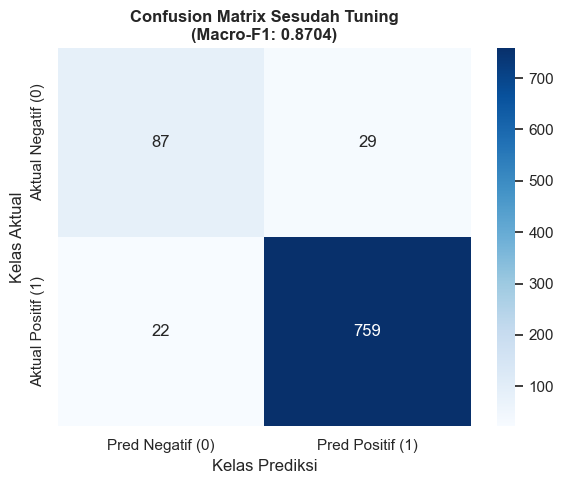

In [10]:
# Evaluasi Akhir: Laporan Klasifikasi Sebelum vs Sesudah Tuning
final_tuned_preds = (val_probs_pos >= best_threshold).astype(int)

print("=" * 70)
print(f"LAPORAN KLASIFIKASI SESUDAH TUNING (C={best_c}, Threshold={best_threshold})")
print(f"Akurasi: {accuracy_score(y_val_strat, final_tuned_preds)*100:.2f}% | Macro-F1: {f1_score(y_val_strat, final_tuned_preds, average='macro'):.4f}")
print("=" * 70)
print(classification_report(y_val_strat, final_tuned_preds, target_names=["Negatif (0)", "Positif (1)"]))

# Visualisasi Heatmap Confusion Matrix Sesudah Tuning
cm_tuned = confusion_matrix(y_val_strat, final_tuned_preds)
plt.figure(figsize=(6, 5))
sns.heatmap(cm_tuned, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Pred Negatif (0)", "Pred Positif (1)"],
            yticklabels=["Aktual Negatif (0)", "Aktual Positif (1)"])
plt.title(f"Confusion Matrix Sesudah Tuning\n(Macro-F1: {best_thresh_row['Macro-F1']:.4f})", fontsize=12, fontweight="bold")
plt.ylabel("Kelas Aktual")
plt.xlabel("Kelas Prediksi")
plt.tight_layout()
plt.show()

## 7. Penyimpanan Model (Model Serialization)
Menyimpan objek Pipeline terbaik yang telah dituning ke dalam berkas `model_sentimen.joblib` (di root dan di folder `model/`) menggunakan `joblib.dump()`.

In [18]:
import joblib
import os
import json

# Simpan pipeline model terbaik ke 'model_sentimen.joblib' di direktori utama sesuai instruksi
joblib.dump(tuned_pipeline, 'model_sentimen.joblib')

# Simpan juga ke dalam folder 'model/' untuk struktur proyek yang rapi
os.makedirs('model', exist_ok=True)
joblib.dump(tuned_pipeline, os.path.join('model', 'model_sentimen.joblib'))

# Simpan juga konfigurasi metadata untuk kemudahan deployment
config_path = os.path.join('model', 'model_config.json')
with open(config_path, 'w') as f:
    json.dump({
        'best_c': best_c,
        'best_threshold': best_threshold,
        'accuracy': float(accuracy_score(y_val_strat, final_tuned_preds)),
        'macro_f1': float(f1_score(y_val_strat, final_tuned_preds, average='macro')),
        'f1_negative': float(f1_score(y_val_strat, final_tuned_preds, pos_label=0)),
        'f1_positive': float(f1_score(y_val_strat, final_tuned_preds, pos_label=1))
    }, f, indent=2)

print('✅ Pipeline model terbaik berhasil disimpan:')
print('   -> model_sentimen.joblib (root direktori)')
print('   -> model/model_sentimen.joblib (folder model)')
print(f'📁 Metadata konfigurasi tersimpan di: {config_path}')

✅ Pipeline model terbaik berhasil disimpan:
   -> model_sentimen.joblib (root direktori)
   -> model/model_sentimen.joblib (folder model)
📁 Metadata konfigurasi tersimpan di: model\model_config.json


## 8. Uji Muat Ulang Model (joblib.load) & Pengujian Ulasan Baru

Sel khusus ini berada di bagian paling bawah notebook untuk memuat ulang model yang tersimpan menggunakan `joblib.load('model_sentimen.joblib')` dan mengujinya pada beberapa contoh kalimat ulasan baru secara mandiri guna membuktikan bahwa model berfungsi penuh tanpa error.

In [19]:
import joblib
import numpy as np

# 1. Muat ulang objek pipeline dari file yang telah disimpan menggunakan joblib.load
file_model = 'model_sentimen.joblib'
model_termuat = joblib.load(file_model)

print(f"📦 Berhasil memuat ulang model dari: '{file_model}'")
print(f"🔍 Tipe Objek: {type(model_termuat)}")
print(f"⚙️ Komponen Pipeline: {list(model_termuat.named_steps.keys())}\n")

# 2. Siapkan berbagai contoh kalimat ulasan baru (positif, negatif, komparatif, dan negasi)
ulasan_baru_uji = [
    "Masterpiece of RPG! The combat is smooth, story is deep, and visuals are breathtaking.",
    "Terrible experience. The game constantly crashes every 10 minutes and save files get corrupted.",
    "Not good at all. I thought it would be fun, but the combat is clunky and gameplay loops are boring.",
    "Great co-op fun with friends! Excellent soundtrack, responsive controls, and challenging boss fights.",
    "Complete waste of money! Full of game-breaking bugs, laggy servers, and aggressive microtransactions.",
    "The story is surprisingly emotional and voice acting is top notch. Definitely worth playing."
]

# 3. Lakukan prediksi sentimen dan probabilitas menggunakan model yang dimuat ulang
prediksi_kelas = model_termuat.predict(ulasan_baru_uji)
probabilitas = model_termuat.predict_proba(ulasan_baru_uji)

# 4. Tampilkan hasil evaluasi pengujian secara terstruktur
print("=" * 88)
print("HASIL PENGUJIAN INFERENSI MODEL TERMUAT (joblib.load) PADA CONTOH ULASAN BARU")
print("=" * 88)

for i, (teks, pred, prob) in enumerate(zip(ulasan_baru_uji, prediksi_kelas, probabilitas), 1):
    label = "POSITIF" if pred == 1 else "NEGATIF"
    confidence = prob[pred] * 100
    print(f"[{i}] Ulasan   : \"{teks}\"")
    print(f"    Prediksi : {label} (Kelas: {pred})")
    print(f"    Keyakinan: {confidence:.2f}%  |  P(Negatif) = {prob[0]:.4f}, P(Positif) = {prob[1]:.4f}")
    print("-" * 88)

print("\n🎉 Pengujian Sukses: Model pipeline berhasil dimuat ulang dan melakukan prediksi tanpa error!")

📦 Berhasil memuat ulang model dari: 'model_sentimen.joblib'
🔍 Tipe Objek: <class 'sklearn.pipeline.Pipeline'>
⚙️ Komponen Pipeline: ['tfidf', 'classifier']

HASIL PENGUJIAN INFERENSI MODEL TERMUAT (joblib.load) PADA CONTOH ULASAN BARU
[1] Ulasan   : "Masterpiece of RPG! The combat is smooth, story is deep, and visuals are breathtaking."
    Prediksi : POSITIF (Kelas: 1)
    Keyakinan: 86.65%  |  P(Negatif) = 0.1335, P(Positif) = 0.8665
----------------------------------------------------------------------------------------
[2] Ulasan   : "Terrible experience. The game constantly crashes every 10 minutes and save files get corrupted."
    Prediksi : NEGATIF (Kelas: 0)
    Keyakinan: 67.63%  |  P(Negatif) = 0.6763, P(Positif) = 0.3237
----------------------------------------------------------------------------------------
[3] Ulasan   : "Not good at all. I thought it would be fun, but the combat is clunky and gameplay loops are boring."
    Prediksi : NEGATIF (Kelas: 0)
    Keyakinan: 93